# GMixOmix demo

This notebook simulates one dataset, matches its cells, and shows the result.

**To run it:** choose **Run > Run All Cells**. With `SIM = "1"`, it should finish in about a minute.

It doesn't change anything in `results/`.

In [1]:
import sys
sys.path.insert(0, "..")  # lets the notebook find the code in this repository

%matplotlib inline
import numpy as np
from IPython.display import Markdown, display

from gmixomix import graph_matching_withD
from results.metrics import calc_stats
from results.plots import plot_latent_space, plot_matching
from simulations import configs, data, run

## 1. Choose a simulation

Change `SIM` to try another one, then run all cells again. Simulations 1 and 2 are quick. Simulations 3 and 4 take a few minutes, and 5 to 10 can take much longer.

In [2]:
SIM = "1"

for name, settings in configs.SIMULATIONS.items():
    print(f"{name:>3}  {settings['description']}")

cfg = configs.SIMULATIONS[SIM]
print("\nSelected:", SIM, "-", cfg["description"])

  1  Identical latent space, adjacency only
  2  Latent space with tiny noise, adjacency only
  3  Latent space with more noise, adjacency only
  4  Same noise as 3 with more neighbours
  5  Latent adjacency helped by noiseless RNA and ATAC
  6  Latent adjacency helped by noisy RNA and ATAC
  7  Graphs from noisy RNA and ATAC, latent space not accessible
  8  As 7, RNA generated with a different D (5% of rows zeroed)
 8'  As 8, with 70% of rows zeroed
  9  As 8, with regularization (c3=20)
 9'  As 8', with stronger regularization (c3=2000)
 10  As 9, with RNA and ATAC converted to Poisson counts

Selected: 1 - Identical latent space, adjacency only


## 2. Simulate the data

Cells: 500
RNA matrix (cells x genes): (500, 100)
ATAC matrix (cells x peaks): (500, 1000)


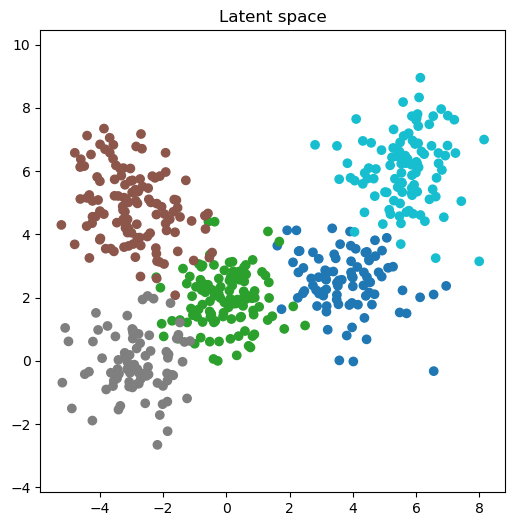

In [3]:
rng1, rng2 = run.make_generators()
Y, labels = data.make_latent_space(rng1, configs.MEANS, run.make_covariances(), configs.NCELLS)
sim = run.simulate(cfg, rng1, rng2, Y, labels)

print("Cells:", Y.shape[0])
print("RNA matrix (cells x genes):", sim["Xa"].shape)
print("ATAC matrix (cells x peaks):", sim["Xb"].shape)
plot_latent_space(Y, labels);

## 3. Match the cells

In [4]:
P_relaxed, P, w = graph_matching_withD(sim["D"], sim["Xa"], sim["Xb"], sim["A"], sim["B"],
                                      verbose=True, **cfg["solver"])

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


Iteration #1,F1=36044.190216777155,F2=0.0,F3=0.0,F4=0.0
Iteration #21,F1=35522.49558510955,F2=0.0,F3=0.0,F4=0.0
Iteration #41,F1=35487.853773955554,F2=0.0,F3=0.0,F4=0.0
Iteration #61,F1=35473.52142155851,F2=0.0,F3=0.0,F4=0.0
Iteration #81,F1=35466.61385256451,F2=0.0,F3=0.0,F4=0.0
Terminating at 81 for tol (APPB1)


## 4. See the results

Each line connects a cell in the left dataset to its match in the right one. Colours show the true clusters, so a good matching mostly connects cells of the same colour.

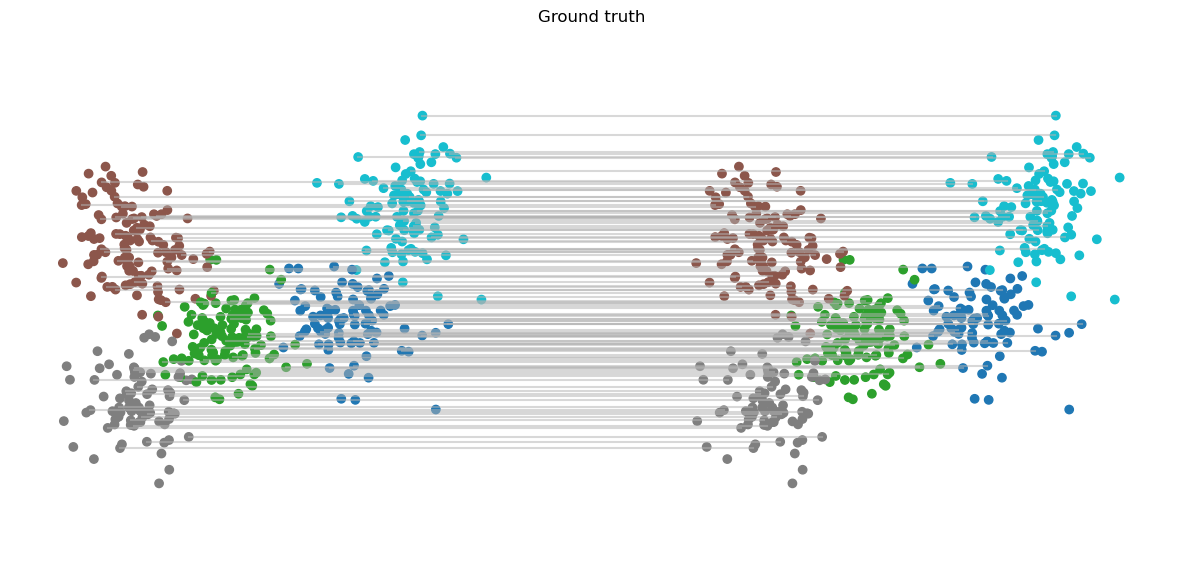

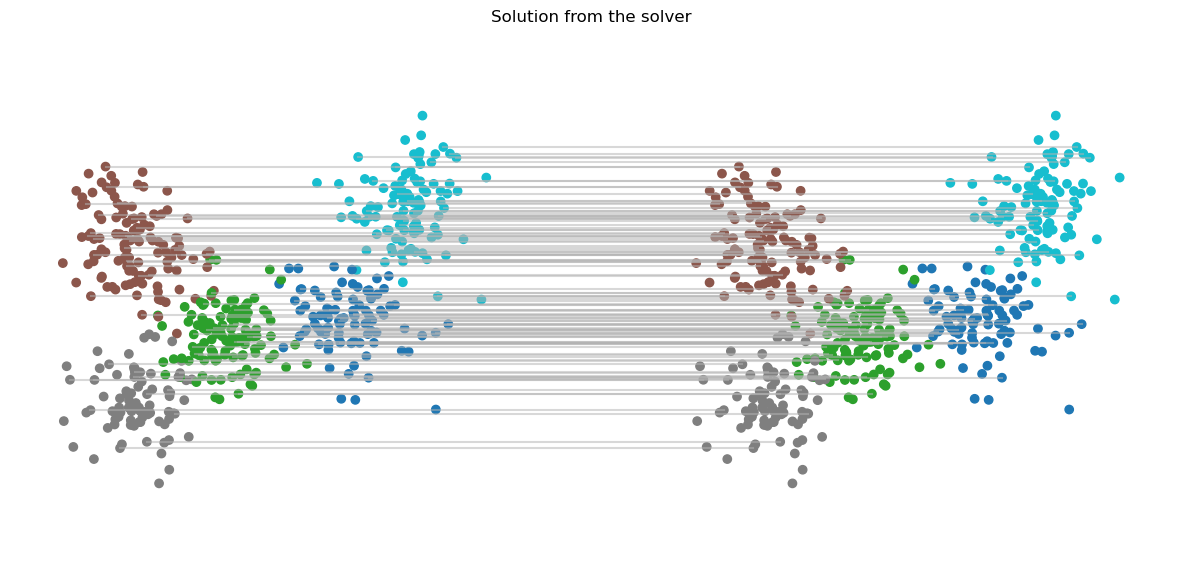

In [5]:
pa, pb = (sim["pca_a"], sim["pca_b"]) if sim["pca_a"] is not None else (sim["Ya"], sim["Yb"])
plot_rng = np.random.default_rng(configs.SEED)
plot_matching(plot_rng, pa[:, :2], pb[:, :2], sim["P0"], sim["labels_a"], sim["labels_b"],
              show_fraction=0.25, title="Ground truth")
plot_matching(plot_rng, pa[:, :2], pb[:, :2], P, sim["labels_a"], sim["labels_b"],
              show_fraction=0.25, title="Solution from the solver");

In [6]:
s = calc_stats(sim["Ya"], sim["Yb"], sim["labels_a"], sim["labels_b"], sim["P0"], P, k=20)
display(Markdown(f"""
| Metric | Before matching | After matching |
|---|---|---|
| Matched cells in the same cluster | {s['label_accuracy_input_I']:.3f} | **{s['label_accuracy']:.3f}** |
| Matched within 20 neighbours of the true cell | {s['relaxed_match_accuracy_input_I']:.3f} | **{s['relaxed_match_accuracy']:.3f}** |
| Average distance to the matched cell | {s['avg_dist_input_I']:.3f} | **{s['avg_dist_solution']:.3f}** |
| Exact cell matches | | **{s['fract_exact_matches']:.3f}** |
"""))


| Metric | Before matching | After matching |
|---|---|---|
| Matched cells in the same cluster | 0.208 | **1.000** |
| Matched within 20 neighbours of the true cell | 0.054 | **1.000** |
| Average distance to the matched cell | 5.294 | **0.000** |
| Exact cell matches | | **1.000** |
